# Field Shift · Phase 3 — Testing (2023–2025)

One single run on years no decision has seen. The models are the Phase 1 models, **frozen** (same files, checked by
SHA-256); the prediction intervals are the ones calibrated in Validation (2018–2022). Nothing is refit, tuned or
recalibrated here. 2026 is left out: its data are incomplete (CHIRPS is missing in 2026-10 and the year is not over),
and nothing is filled in. 2022 is read only as history for the lags of January 2023.

At the end the tested models are packaged as the **final models** (`artifacts/final_model/`) with their model card.
Results and reading: `docs/ML_PHASE3_TESTING.md`.

## 1. Environment

In [1]:
import sys, json, shutil, platform
from pathlib import Path
import numpy as np, pandas as pd, scipy, xgboost as xgb, matplotlib
import matplotlib.pyplot as plt

ML_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_DIR))
from fs_ml import data as D, features as F, evaluate as E

SEED = 42
pd.set_option("display.width", 170, "display.max_columns", 30)
SPLITS = {"training": (1998, 2017), "validation": (2018, 2022), "testing": (2023, 2025)}
TEST = SPLITS["testing"]; LOAD = (TEST[0] - 1, TEST[1])
N_BOOT, BLOCK_DEG = 1000, 0.2
P1, P2 = ML_DIR / "artifacts" / "phase1_training", ML_DIR / "artifacts" / "phase2_validation"
ART = ML_DIR / "artifacts" / "phase3_testing"; ART.mkdir(parents=True, exist_ok=True)
FINAL = ML_DIR / "artifacts" / "final_model"; FINAL.mkdir(parents=True, exist_ok=True)
# Same rules as Validation (docs/ML_PHASE1_TRAINING.md §10), applied here as the final reference.
CRITERIA = {"sm_root_monthly": {"A_skill_min": 0.20, "C_rmse_max": 0.04, "D_abs_bias_max": 0.01},
            "ndvi_quarterly": {"A_skill_min": 0.10, "C_rmse_max": None, "D_abs_bias_max": 0.03},
            "F_coverage_90": (0.87, 0.93)}
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": scipy.__version__, "xgboost": xgb.__version__}
VERSIONS

{'python': '3.14.6',
 'numpy': '2.5.4',
 'pandas': '3.1.1',
 'scipy': '1.18.1',
 'xgboost': '3.4.1'}

## 2. Frozen models and the intervals fixed in Validation

In [2]:
MODELS = {}
for name in ["sm_root_monthly", "ndvi_quarterly"]:
    d = P1 / name
    meta = json.loads((d / "metadata.json").read_text()); prep = json.loads((d / "preprocessing.json").read_text())
    val = json.loads((P2 / name / "validation_report.json").read_text())
    sha = D.sha256(d / "model.ubj")
    assert sha == val["model_sha256"], "model changed after Validation"
    m = xgb.XGBRegressor(); m.load_model(d / "model.ubj")
    by_cell = pd.read_parquet(d / "baseline_climatology_by_cell.parquet"); by_season = pd.read_parquet(d / "baseline_climatology_by_season.parquet")
    keys = list(by_cell.columns[:-1]); season = by_season.columns[0]
    MODELS[name] = {"model": m, "meta": meta, "prep": prep, "val": val, "sha": sha, "features": prep["feature_names_in_order"],
                    "target": meta["target"]["column"], "unit": meta["target"]["unit"],
                    "clim": {"by_cell": by_cell.set_index(keys)["climatology"], "by_season": by_season.set_index(season)["climatology"], "keys": keys, "season": season},
                    "widths": val["intervals_final_2018_2022"]}
    print(name, "| sha256 same as Validation:", sha[:16], "| 90% widths by season:", {k: round(v, 4) for k, v in MODELS[name]["widths"]["by_season_half_width_90"].items()})

sm_root_monthly | sha256 same as Validation: a4bbaf1397c43e2c | 90% widths by season: {'dry May-Dec': 0.0128, 'wet Jan-Apr': 0.0295}
ndvi_quarterly | sha256 same as Validation: effe57ea2506d509 | 90% widths by season: {'Q1': 0.184, 'Q2': 0.2031, 'Q3': 0.1502, 'Q4': 0.1229}


## 3. New NASA POWER files (2023–2025)

In [3]:
power, rows = {}, []
for p in ["t2m", "rh2m", "ws2m", "allsky"]:
    df, info = D.load_power(f"power_{p}_2023_2025", TEST)
    ref, _ = D.load_power(f"power_{p}", SPLITS["training"])
    col = df.columns[-1]
    same = set(map(tuple, df[["power_lat", "power_lon"]].drop_duplicates().values)) == set(map(tuple, ref[["power_lat", "power_lon"]].drop_duplicates().values))
    power[p] = df
    rows.append({"file": D.RAW_FILES[f"power_{p}_2023_2025"].split("/")[-1], "parameter": info["parameter"],
                 "dates": info["header"].splitlines()[2].split(": ")[1], "rows": info["rows_wide"], "duplicates": info["duplicate_rows"],
                 "-999": info["missing_-999"], "same_grid_as_training": same,
                 "range_2023_2025": f"{df[col].min():.2f}..{df[col].max():.2f}", "range_1998_2017": f"{ref[col].min():.2f}..{ref[col].max():.2f}"})
pd.DataFrame(rows)

,file,parameter,dates,rows,duplicates,-999,same_grid_as_training,range_2023_2025,range_1998_2017
0,Temperature at 2 Meters_Monthly_2023_2025.csv,T2M,01/01/2023 through 12/31/2025 in LST,60,0,0,True,13.32..29.33,12.13..29.35
1,Relative Humidity at 2 Meters_Monthly_2023_202...,RH2M,01/01/2023 through 12/31/2025 in LST,60,0,0,True,47.15..97.51,46.42..97.13
2,Wind Speed at 2 Meters_Monthly_2023_2025.csv,WS2M,01/01/2023 through 12/31/2025 in LST,60,0,0,True,0.94..5.68,1.02..6.02
3,All Sky Surface Shortwave Downward Irradiance_...,ALLSKY_SFC_SW_DWN,01/01/2023 through 12/31/2025 in LST,18,0,0,True,10.59..24.16,9.20..25.80


## 4. GEE tables for 2022–2025 (2022 = lag history only; 2026 not loaded)

In [4]:
monthly, info_m = D.load_gee_monthly(LOAD); veg, info_q = D.load_gee_quarterly(LOAD)
print("monthly:", info_m); print("quarterly:", info_q)
print("monthly missing values:", monthly.isna().sum().to_dict())
print("Cells with NDVI per quarter, 2023-2025 (of 2585):")
veg[veg.year.between(*TEST)].groupby(["year", "quarter"]).size().unstack("quarter")

monthly: {'rows_total': 1089554, 'rows_kept': 151152, 'rows_outside_window_not_used': 938402, 'index_prefix_matches_month': True}
quarterly: {'rows_total': 181580, 'rows_kept': 40126, 'rows_outside_window_not_used': 141454}
monthly missing values: {'cell_id': 0, 'date': 0, 'rain_mm': 0, 't2m_c': 1104, 'pet_mm': 1104, 'sm_surface_m3m3': 1104, 'sm_root_m3m3': 1104}
Cells with NDVI per quarter, 2023-2025 (of 2585):


quarter,1,2,3,4
year,,,,
2023,2408,2564,2577,2558
2024,2428,2585,2566,2580
2025,2296,2570,2407,2517


In [5]:
rain = monthly.groupby("date").rain_mm.mean()
print("Wettest months 2022-2025 (mean over cells, mm) — the 2023 coastal El Niño should show up:")
rain.sort_values(ascending=False).head(6).round(1)

Wettest months 2022-2025 (mean over cells, mm) — the 2023 coastal El Niño should show up:


date
2023-03-01    118.7
2023-04-01     68.9
2025-03-01     40.3
2022-03-01     39.5
2023-02-01     39.4
2025-02-01     35.4
Name: rain_mm, dtype: float64

## 5. Test tables, built with the same code as Training

In [6]:
gaez = {k: D.load_gaez(k)[0] for k in F.GAEZ_FEATURES}
merra = power["t2m"].merge(power["rh2m"], on=["power_lat", "power_lon", "date"]).merge(power["ws2m"], on=["power_lat", "power_lon", "date"])
ceres = power["allsky"]
cells = F.static_cells(D.cells_from_ids(monthly.cell_id), gaez, merra[["power_lat", "power_lon"]].drop_duplicates().reset_index(drop=True),
                       ceres[["power_lat", "power_lon"]].drop_duplicates().reset_index(drop=True))
cells["province"] = D.provinces_of(cells); cells["block"] = E.spatial_blocks(cells.lat, cells.lon, BLOCK_DEG)
monthly_panel = F.build_monthly_panel(monthly, cells.drop(columns=["province", "block"]), merra, ceres)
quarterly_panel = F.build_quarterly_panel(monthly_panel, veg)
extra = cells.set_index("cell_id")[["province", "block"]]
monthly_panel = monthly_panel.join(extra, on="cell_id"); quarterly_panel = quarterly_panel.join(extra, on="cell_id")
monthly_panel["season"] = np.where(monthly_panel.month <= 4, "wet Jan-Apr", "dry May-Dec")
quarterly_panel["season"] = "Q" + quarterly_panel.quarter.astype(str)
EVAL = {"sm_root_monthly": monthly_panel, "ndvi_quarterly": quarterly_panel}

## 6. Predictions and baselines

In [7]:
V = {}
for name, M in MODELS.items():
    df = EVAL[name]; t = M["target"]
    v = df[df.year.between(*TEST) & df[t].notna()].reset_index(drop=True)
    pred = M["model"].predict(v[M["features"]]); clim = E.predict_climatology(M["clim"], v)
    lag = "sm_root_m3m3_lag1" if name.startswith("sm") else "ndvi_lag1"
    pers = np.where(v[lag].isna(), clim, v[lag])
    V[name] = {"rows": v, "y": v[t].to_numpy(), "preds": {"XGBoost": pred, "climatology": clim, "persistence": pers},
               "best_baseline": M["val"]["best_baseline"]}   # fixed in Validation
    print(name, "| test rows:", len(v), "| cells:", v.cell_id.nunique(), "| baseline to beat (from Validation):", V[name]["best_baseline"])

sm_root_monthly | test rows: 112536 | cells: 3126 | baseline to beat (from Validation): persistence
ndvi_quarterly | test rows: 30056 | cells: 2585 | baseline to beat (from Validation): climatology


## 7. Error metrics with 95 % confidence intervals (block bootstrap)

In [8]:
def ci_table(name, mask=None):
    R = V[name]; m = slice(None) if mask is None else mask
    return E.block_bootstrap(R["y"][m], {k: p[m] for k, p in R["preds"].items()}, R["rows"]["block"].to_numpy()[m],
                             reference="XGBoost", n_boot=N_BOOT, seed=SEED)
OVERALL = {}
for name, R in V.items():
    OVERALL[name] = ci_table(name)
    print(f"\n=== {name} ({MODELS[name]['unit']}) — testing 2023-2025, n = {len(R['y'])}"); display(OVERALL[name].round(4))
    if name.startswith("sm"):
        print("MAPE (%):", round(float(np.mean(np.abs(R["preds"]["XGBoost"] - R["y"]) / R["y"]) * 100), 2))


=== sm_root_monthly (m3/m3) — testing 2023-2025, n = 112536


,model,metric,value,ci_low,ci_high
0,XGBoost,MAE,0.0113,0.0103,0.0123
1,XGBoost,RMSE,0.0198,0.0185,0.0211
2,XGBoost,R2,0.9615,0.9541,0.9676
3,XGBoost,bias,-0.0030,-0.0036,-0.0024
4,XGBoost,skill vs climatology,0.4742,0.4343,0.5126
5,XGBoost,skill vs persistence,0.4600,0.4357,0.4857
6,climatology,MAE,0.0261,0.0240,0.0281
7,climatology,RMSE,0.0376,0.0349,0.0402
8,climatology,R2,0.8609,0.8292,0.8857
9,climatology,bias,-0.0127,-0.0157,-0.0094


MAPE (%): 5.1

=== ndvi_quarterly (index) — testing 2023-2025, n = 30056


,model,metric,value,ci_low,ci_high
0,XGBoost,MAE,0.0938,0.0898,0.0973
1,XGBoost,RMSE,0.1262,0.1208,0.1308
2,XGBoost,R2,0.5258,0.4774,0.5723
3,XGBoost,bias,-0.0264,-0.0322,-0.0204
4,XGBoost,skill vs climatology,0.2137,0.1405,0.2879
5,XGBoost,skill vs persistence,0.3141,0.2783,0.3464
6,climatology,MAE,0.1185,0.1086,0.1301
7,climatology,RMSE,0.1605,0.1465,0.1765
8,climatology,R2,0.2331,0.0555,0.3642
9,climatology,bias,-0.0826,-0.0987,-0.0696


In [9]:
def by_group(name, col):
    R = V[name]; best = R["best_baseline"]; out = []
    for g in sorted(R["rows"][col].unique(), key=str):
        mask = (R["rows"][col] == g).to_numpy()
        t = ci_table(name, mask).set_index(["model", "metric"])
        out.append({col: g, "n": int(mask.sum()), "MAE": t.loc[("XGBoost", "MAE"), "value"], "RMSE": t.loc[("XGBoost", "RMSE"), "value"],
                    f"RMSE {best}": t.loc[(best, "RMSE"), "value"], "bias": t.loc[("XGBoost", "bias"), "value"], "R2": t.loc[("XGBoost", "R2"), "value"],
                    "skill": t.loc[("XGBoost", f"skill vs {best}"), "value"], "skill_ci_low": t.loc[("XGBoost", f"skill vs {best}"), "ci_low"],
                    "skill_ci_high": t.loc[("XGBoost", f"skill vs {best}"), "ci_high"]})
    return pd.DataFrame(out)
GROUPS = {name: {col: by_group(name, col) for col in ["year", "province", "season"]} for name in V}
for name in V:
    for col, tab in GROUPS[name].items():
        print(f"\n{name} by {col} (skill vs {V[name]['best_baseline']}, 95% CI)"); display(tab.round(4))


sm_root_monthly by year (skill vs persistence, 95% CI)


,year,n,MAE,RMSE,RMSE persistence,bias,R2,skill,skill_ci_low,skill_ci_high
0,2023,37512,0.0135,0.0231,0.0451,-0.0046,0.9461,0.4883,0.4538,0.5241
1,2024,37512,0.0104,0.0186,0.0233,-0.0019,0.9648,0.2019,0.1253,0.2787
2,2025,37512,0.0101,0.0172,0.0382,-0.0025,0.9712,0.5484,0.5165,0.5790



sm_root_monthly by province (skill vs persistence, 95% CI)


,province,n,MAE,RMSE,RMSE persistence,bias,R2,skill,skill_ci_low,skill_ci_high
0,Chiclayo,17820,0.0105,0.0188,0.0307,-0.0017,0.9375,0.3886,0.2745,0.4407
1,Ferreñafe,9216,0.0135,0.0214,0.0404,-0.0038,0.9405,0.4700,0.4477,0.5001
2,Lambayeque,43164,0.0112,0.0214,0.0368,-0.0031,0.9287,0.4180,0.3880,0.4449
3,outside,42336,0.0113,0.0180,0.0379,-0.0032,0.9688,0.5244,0.4863,0.5542



sm_root_monthly by season (skill vs persistence, 95% CI)


,season,n,MAE,RMSE,RMSE persistence,bias,R2,skill,skill_ci_low,skill_ci_high
0,dry May-Dec,75024,0.0072,0.0119,0.0274,-0.0012,0.9816,0.5670,0.541,0.5928
1,wet Jan-Apr,37512,0.0196,0.0299,0.0503,-0.0066,0.9344,0.4054,0.378,0.4361


... (2 outputs left out)


ndvi_quarterly by province (skill vs climatology, 95% CI)


,province,n,MAE,RMSE,RMSE climatology,bias,R2,skill,skill_ci_low,skill_ci_high
0,Chiclayo,5653,0.0906,0.1209,0.1509,-0.0282,0.4307,0.1988,0.0940,0.3254
1,Ferreñafe,2297,0.0913,0.1242,0.1352,-0.0389,0.4836,0.0814,-0.0502,0.1582
2,Lambayeque,12673,0.0976,0.1347,0.1807,-0.0229,0.4730,0.2544,0.1511,0.3482
3,outside,9433,0.0911,0.1177,0.1419,-0.0270,0.5467,0.1703,0.0734,0.2521



ndvi_quarterly by season (skill vs climatology, 95% CI)


,season,n,MAE,RMSE,RMSE climatology,bias,R2,skill,skill_ci_low,skill_ci_high
0,Q1,7132,0.0934,0.1260,0.1592,-0.0358,0.5411,0.2089,0.1329,0.2843
1,Q2,7719,0.1330,0.1695,0.1930,-0.0519,0.2581,0.1218,0.0474,0.2000
2,Q3,7550,0.0817,0.1045,0.1495,-0.0040,0.4610,0.3013,0.2225,0.3709
3,Q4,7655,0.0664,0.0895,0.1338,-0.0140,0.6568,0.3311,0.2565,0.3955


In [10]:
# Month by month (soil water) and quarter by quarter (NDVI): where the error concentrates
TIMELINE = {}
for name, R in V.items():
    v = R["rows"].assign(err=R["preds"]["XGBoost"] - R["y"], err_base=R["preds"][R["best_baseline"]] - R["y"])
    if "date" not in v: v["date"] = pd.to_datetime(dict(year=v.year, month=(v.quarter - 1) * 3 + 1, day=1))
    TIMELINE[name] = v.groupby("date").agg(rmse=("err", lambda e: float(np.sqrt((e ** 2).mean()))),
                                           rmse_baseline=("err_base", lambda e: float(np.sqrt((e ** 2).mean()))), bias=("err", "mean"))
    print(name, "— 4 worst periods:"); display(TIMELINE[name].sort_values("rmse", ascending=False).head(4).round(4))

sm_root_monthly — 4 worst periods:


,rmse,rmse_baseline,bias
date,,,
2023-03-01,0.0533,0.0895,-0.0367
2024-01-01,0.0381,0.0500,-0.0228
2023-04-01,0.0337,0.0588,-0.0236
2025-03-01,0.0275,0.0691,-0.0138


ndvi_quarterly — 4 worst periods:


,rmse,rmse_baseline,bias
date,,,
2023-04-01,0.2209,0.2514,-0.1524
2024-01-01,0.1483,0.1813,-0.0621
2025-04-01,0.1472,0.1706,-0.0514
2024-04-01,0.1261,0.1401,0.0474


## 8. Confidence: do the Validation intervals hold on 2023–2025?

In [11]:
COVER = {}
for name, R in V.items():
    res = np.abs(R["preds"]["XGBoost"] - R["y"]); blk = R["rows"]["block"].to_numpy(); seas = R["rows"]["season"].to_numpy()
    w = MODELS[name]["widths"]; rows = []
    for k, h in w["global_half_width"].items():
        c, lo, hi = E.coverage_ci(res <= h, blk); rows.append({"interval": f"global {k}", "half_width": h, "coverage": c, "ci_low": lo, "ci_high": hi})
    hs = pd.Series(seas).map(w["by_season_half_width_90"]).to_numpy()
    c, lo, hi = E.coverage_ci(res <= hs, blk); rows.append({"interval": "by season 90%", "half_width": None, "coverage": c, "ci_low": lo, "ci_high": hi})
    for s in sorted(set(seas)):
        m = seas == s; c, lo, hi = E.coverage_ci(res[m] <= w["by_season_half_width_90"][s], blk[m])
        rows.append({"interval": f"  {s} 90%", "half_width": w["by_season_half_width_90"][s], "coverage": c, "ci_low": lo, "ci_high": hi})
    yr = R["rows"].year.to_numpy()
    for y in sorted(set(yr)):
        m = yr == y; c, lo, hi = E.coverage_ci(res[m] <= hs[m], blk[m])
        rows.append({"interval": f"  {y} (by season 90%)", "half_width": None, "coverage": c, "ci_low": lo, "ci_high": hi})
    COVER[name] = pd.DataFrame(rows)
    print(f"\n=== {name}"); display(COVER[name].round(4))


=== sm_root_monthly


,interval,half_width,coverage,ci_low,ci_high
0,global 80%,0.0107,0.7025,0.6683,0.7377
1,global 90%,0.0187,0.8206,0.7981,0.8440
2,global 95%,0.0285,0.8891,0.8751,0.9040
3,by season 90%,NaN,0.8159,0.7926,0.8401
4,dry May-Dec 90%,0.0128,0.8404,0.8061,0.8719
5,wet Jan-Apr 90%,0.0295,0.7667,0.7323,0.8010
6,2023 (by season 90%),NaN,0.7724,0.7530,0.7931
7,2024 (by season 90%),NaN,0.8359,0.7891,0.8799
8,2025 (by season 90%),NaN,0.8393,0.8203,0.8599



=== ndvi_quarterly


,interval,half_width,coverage,ci_low,ci_high
0,global 80%,0.1206,0.7196,0.7014,0.7392
1,global 90%,0.1693,0.8458,0.8327,0.8607
2,global 95%,0.2189,0.9163,0.9061,0.9275
3,by season 90%,NaN,0.8396,0.8264,0.8547
4,Q1 90%,0.1840,0.8636,0.8331,0.8934
5,Q2 90%,0.2031,0.7939,0.7551,0.8343
6,Q3 90%,0.1502,0.8609,0.8386,0.8820
7,Q4 90%,0.1229,0.8425,0.8118,0.8714
8,2023 (by season 90%),NaN,0.8073,0.7772,0.8387
9,2024 (by season 90%),NaN,0.8733,0.8573,0.8900


## 9. Inputs outside the training range

In [12]:
OOD = {}
for name, R in V.items():
    X = R["rows"][MODELS[name]["features"]]; b = MODELS[name]["prep"]["training_feature_bounds"]
    soft, hard = E.out_of_range(X, b).values, E.out_of_range(X, b, strict=True).values
    per_feat = {c: float(((X[c] < b[c]["p01"]) | (X[c] > b[c]["p99"])).mean()) for c in X.columns}
    y, p = R["y"], R["preds"]["XGBoost"]
    OOD[name] = {"share_outside_p01_p99": float(soft.mean()), "share_outside_min_max": float(hard.mean()),
                 "RMSE_inside": E.regression_metrics(y[~soft], p[~soft])["RMSE"],
                 "RMSE_outside_p01_p99": E.regression_metrics(y[soft], p[soft])["RMSE"] if soft.any() else None,
                 "RMSE_outside_min_max": E.regression_metrics(y[hard], p[hard])["RMSE"] if hard.any() else None,
                 "top_features": dict(sorted(per_feat.items(), key=lambda kv: -kv[1])[:5])}
    print(name, json.dumps(OOD[name], indent=1))

sm_root_monthly {
 "share_outside_p01_p99": 0.20644060567285136,
 "share_outside_min_max": 0.006948887467121632,
 "RMSE_inside": 0.020543258665592815,
 "RMSE_outside_p01_p99": 0.016614236760659283,
 "RMSE_outside_min_max": 0.009466462968975048,
 "top_features": {
  "rain_mm_sum6": 0.03765906021184332,
  "power_ws2m_ms": 0.037232530034833296,
  "t2m_c": 0.03701926494632828,
  "pet_mm": 0.03250515390630554,
  "pet_mm_lag1": 0.03098564015070733
 }
}
ndvi_quarterly {
 "share_outside_p01_p99": 0.18438914027149322,
 "share_outside_min_max": 0.012909236092627096,
 "RMSE_inside": 0.12412644162532917,
 "RMSE_outside_p01_p99": 0.13504932925162438,
 "RMSE_outside_min_max": 0.0996713601949632,
 "top_features": {
  "q_t2m_c": 0.035899653979238756,
  "q_pet_mm": 0.027215863721054032,
  "q_power_rh2m_pct": 0.026250998136811286,
  "q_rain_mm": 0.0208943305829119,
  "q_rain_mm_lag1": 0.020761245674740483
 }
}


## 10. Final check against the acceptance rules

In [13]:
DECISION = {}
for name, R in V.items():
    c = CRITERIA[name]; best = R["best_baseline"]; t = OVERALL[name].set_index(["model", "metric"])
    sk, rmse, bias = t.loc[("XGBoost", f"skill vs {best}")], t.loc[("XGBoost", "RMSE")], t.loc[("XGBoost", "bias")]
    prov = GROUPS[name]["province"]; prov = prov[prov.province != "outside"]
    wy, wp = GROUPS[name]["year"].skill.min(), prov.skill.min()
    cov = COVER[name].set_index("interval").loc["global 90%", "coverage"]; cov_s = COVER[name].set_index("interval").loc["by season 90%", "coverage"]
    lo, hi = CRITERIA["F_coverage_90"]
    tab = pd.DataFrame([
        ("A", f"skill vs {best} >= {c['A_skill_min']}", f"{sk.value:.3f} [{sk.ci_low:.3f}, {sk.ci_high:.3f}]", sk.value >= c["A_skill_min"]),
        ("B", "lower 95% CI of that skill > 0", f"{sk.ci_low:.3f}", sk.ci_low > 0),
        ("C", f"RMSE <= {c['C_rmse_max']}" if c["C_rmse_max"] else "RMSE (report only)", f"{rmse.value:.4f} [{rmse.ci_low:.4f}, {rmse.ci_high:.4f}]",
         (rmse.value <= c["C_rmse_max"]) if c["C_rmse_max"] else None),
        ("D", f"|bias| <= {c['D_abs_bias_max']}", f"{bias.value:.4f} [{bias.ci_low:.4f}, {bias.ci_high:.4f}]", abs(bias.value) <= c["D_abs_bias_max"]),
        ("E", "skill >= 0 in every year and province", f"worst year {wy:.3f}, worst province {wp:.3f}", min(wy, wp) >= 0),
        ("F", f"90% coverage in [{lo}, {hi}]", f"global {cov:.3f} · by season {cov_s:.3f}", lo <= cov_s <= hi),
        ("G", "share outside training p01-p99 (report)", f"{OOD[name]['share_outside_p01_p99']:.3f}", None),
    ], columns=["criterion", "rule", "result", "pass"])
    failed = list(tab.loc[tab["pass"] == False, "criterion"])
    verdict = "PASSES TESTING" if not failed else "TESTING SHOWS WEAKNESSES: " + ", ".join(failed)
    DECISION[name] = {"table": tab, "verdict": verdict}
    print(f"\n=== {name}: {verdict}"); display(tab)


=== sm_root_monthly: TESTING SHOWS WEAKNESSES: F


,criterion,rule,result,pass
0,A,skill vs persistence >= 0.2,"0.460 [0.436, 0.486]",True
1,B,lower 95% CI of that skill > 0,0.436,True
2,C,RMSE <= 0.04,"0.0198 [0.0185, 0.0211]",True
3,D,|bias| <= 0.01,"-0.0030 [-0.0036, -0.0024]",True
4,E,skill >= 0 in every year and province,"worst year 0.202, worst province 0.389",True
5,F,"90% coverage in [0.87, 0.93]",global 0.821 · by season 0.816,False
6,G,share outside training p01-p99 (report),0.206,None



=== ndvi_quarterly: TESTING SHOWS WEAKNESSES: F


,criterion,rule,result,pass
0,A,skill vs climatology >= 0.1,"0.214 [0.141, 0.288]",True
1,B,lower 95% CI of that skill > 0,0.141,True
2,C,RMSE (report only),"0.1262 [0.1208, 0.1308]",None
3,D,|bias| <= 0.03,"-0.0264 [-0.0322, -0.0204]",True
4,E,skill >= 0 in every year and province,"worst year 0.168, worst province 0.081",True
5,F,"90% coverage in [0.87, 0.93]",global 0.846 · by season 0.840,False
6,G,share outside training p01-p99 (report),0.184,None


## 11. Figures

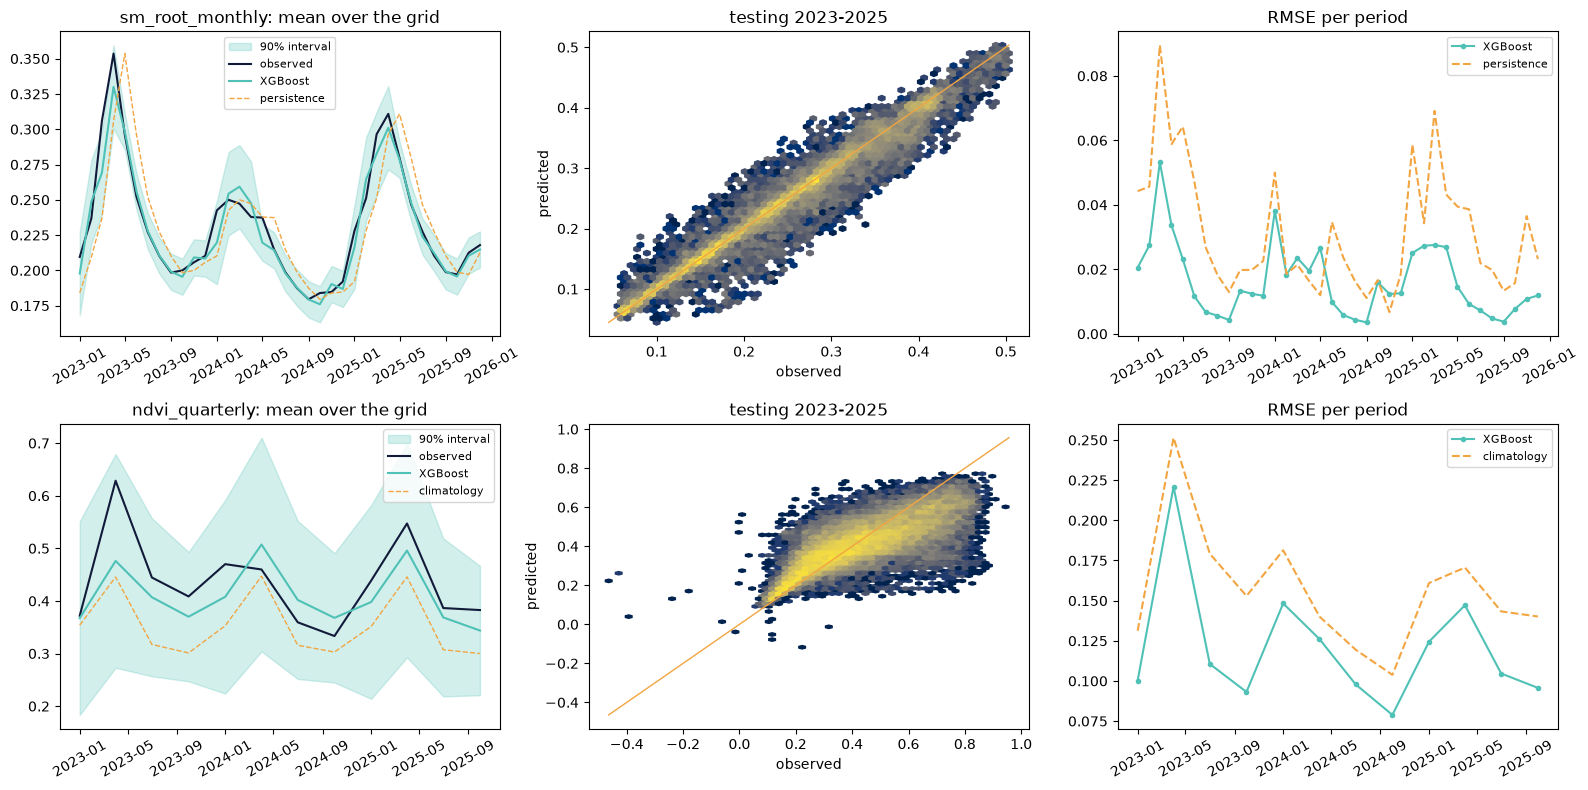

In [14]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for row, (name, R) in zip(ax, V.items()):
    v = R["rows"].assign(pred=R["preds"]["XGBoost"], obs=R["y"], base=R["preds"][R["best_baseline"]])
    if "date" not in v: v["date"] = pd.to_datetime(dict(year=v.year, month=(v.quarter - 1) * 3 + 1, day=1))
    ts = v.groupby("date")[["obs", "pred", "base"]].mean()
    s = R["rows"].assign(w=R["rows"]["season"].map(MODELS[name]["widths"]["by_season_half_width_90"]))
    s["date"] = v["date"]; w = s.groupby("date").w.mean()
    row[0].fill_between(ts.index, ts.pred - w, ts.pred + w, color="#4FC1B6", alpha=0.25, label="90% interval")
    row[0].plot(ts.index, ts.obs, color="#121A3A", lw=1.5, label="observed"); row[0].plot(ts.index, ts.pred, color="#4FC1B6", lw=1.5, label="XGBoost")
    row[0].plot(ts.index, ts.base, color="#F2A541", lw=1, ls="--", label=R["best_baseline"]); row[0].legend(fontsize=8); row[0].set_title(f"{name}: mean over the grid")
    row[1].hexbin(v.obs, v.pred, gridsize=60, bins="log", cmap="cividis")
    lim = [min(v.obs.min(), v.pred.min()), max(v.obs.max(), v.pred.max())]; row[1].plot(lim, lim, color="#F2A541", lw=1)
    row[1].set_xlabel("observed"); row[1].set_ylabel("predicted"); row[1].set_title("testing 2023-2025")
    tl = TIMELINE[name]
    row[2].plot(tl.index, tl.rmse, color="#4FC1B6", marker="o", ms=3, label="XGBoost"); row[2].plot(tl.index, tl.rmse_baseline, color="#F2A541", ls="--", label=R["best_baseline"])
    row[2].set_title("RMSE per period"); row[2].legend(fontsize=8)
    for a in (row[0], row[2]): a.tick_params(axis="x", labelrotation=30)
plt.tight_layout(); fig.savefig(ART / "phase3_testing.png", dpi=110); plt.show()

## 12. Saving the test report and packaging the final models

In [15]:
PHASES = {}
for name in V:
    out = ART / name; out.mkdir(exist_ok=True)
    OVERALL[name].to_csv(out / "metrics_ci.csv", index=False)
    for col, tab in GROUPS[name].items(): tab.to_csv(out / f"metrics_by_{col}.csv", index=False)
    TIMELINE[name].to_csv(out / "error_timeline.csv"); COVER[name].to_csv(out / "intervals_coverage.csv", index=False)
    DECISION[name]["table"].to_csv(out / "criteria.csv", index=False)
    rep = {"model_sha256": MODELS[name]["sha"], "years": TEST, "n_rows": int(len(V[name]["y"])), "baseline": V[name]["best_baseline"],
           "verdict": DECISION[name]["verdict"], "criteria": DECISION[name]["table"].to_dict("records"),
           "metrics_ci": OVERALL[name].to_dict("records"), "out_of_range": OOD[name], "intervals_coverage": COVER[name].to_dict("records")}
    (out / "test_report.json").write_text(json.dumps(rep, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))

    # final package: the tested model, unchanged
    M = MODELS[name]; fd = FINAL / name; fd.mkdir(exist_ok=True)
    shutil.copy2(P1 / name / "model.ubj", fd / "model.ubj"); shutil.copy2(P1 / name / "preprocessing.json", fd / "preprocessing.json")
    for f in ["baseline_climatology_by_cell.parquet", "baseline_climatology_by_season.parquet"]: shutil.copy2(P1 / name / f, fd / f)
    cs = COVER[name].set_index("interval")
    (fd / "intervals.json").write_text(json.dumps({
        "method": "split conformal, absolute errors of Validation 2018-2022, one width per season", "nominal": 0.90,
        "half_width_90_by_season": M["widths"]["by_season_half_width_90"], "half_width_global": M["widths"]["global_half_width"],
        "tested_coverage": {"by_season_90": float(cs.loc["by season 90%", "coverage"]), "ci95": [float(cs.loc["by season 90%", "ci_low"]), float(cs.loc["by season 90%", "ci_high"])],
                            "global_90": float(cs.loc["global 90%", "coverage"]), "years": TEST},
        "warning": "Not a probability. Coverage measured on 2023-2025; it can be lower in extreme years."}, indent=2))
    pick = lambda df, model, metric: df.set_index(["model", "metric"]).loc[(model, metric)]
    def phase_metrics(df, best):
        r = {m: {"value": float(pick(df, "XGBoost", m)["value"]), "ci95": [float(pick(df, "XGBoost", m)["ci_low"]), float(pick(df, "XGBoost", m)["ci_high"])]}
             for m in ["MAE", "RMSE", "R2", "bias", f"skill vs {best}"]}
        return r
    val_ci = pd.read_csv(P2 / name / "metrics_ci.csv")
    st1 = pd.DataFrame(M["meta"]["internal_training_diagnostics"]["stage1_metrics"]).query("model == 'XGBoost'").set_index("subset")
    card = {
        "name": name, "version": "1.0 (tested)", "estimator": "xgboost.XGBRegressor", "sha256": M["sha"],
        "target": M["meta"]["target"], "features_in_order": M["features"],
        "hyperparameters": M["meta"]["hyperparameters_final_refit"], "trees": M["meta"]["best_number_of_trees"], "random_seed": 42,
        "data": {"training": "1998-2017", "validation": "2018-2022", "testing": "2023-2025", "excluded": "2026 (incomplete)",
                 "rows": {"training": M["meta"]["rows"]["training_with_target"], "testing": int(len(V[name]["y"]))},
                 "sources": ["CHIRPS rain", "ERA5-Land temperature, potential evaporation, soil water", "satellite NDVI composite (GEE)",
                             "NASA POWER RH2M, WS2M, ALLSKY_SFC_SW_DWN", "FAO GAEZ soil classes"]},
        "metrics": {"training_internal_2016_2017": {k: float(st1.loc["internal ES 2016-2017", k]) for k in ["MAE", "RMSE", "R2", "bias"]},
                    "validation_2018_2022": phase_metrics(val_ci, V[name]["best_baseline"]),
                    "testing_2023_2025": phase_metrics(OVERALL[name], V[name]["best_baseline"])},
        "baseline_to_beat": V[name]["best_baseline"], "test_verdict": DECISION[name]["verdict"],
        "out_of_range_share_test": OOD[name]["share_outside_p01_p99"],
        "intended_use": "Explore how the model responds to changed weather for a 2 km cell of the Lambayeque grid, with an interval and an out-of-range warning.",
        "not_for": ["A measurement of a specific field", "Irrigated fields (ERA5-Land has no irrigation)", "Forecasts of real future dates",
                    "Causal claims", "Crop yield, crop type or risk classes"],
        "library_versions": VERSIONS}
    (fd / "model_card.json").write_text(json.dumps(card, indent=2, ensure_ascii=False, default=str))
    PHASES[name] = card["metrics"]
(ART / "phase3_summary.json").write_text(json.dumps({"years": TEST, "2026": "excluded, incomplete", "models_refit": False, "intervals_recalibrated": False,
    "bootstrap": {"n": N_BOOT, "block_deg": BLOCK_DEG, "level": 0.95}, "verdicts": {n: DECISION[n]["verdict"] for n in V}}, indent=2))
print(json.dumps({n: DECISION[n]["verdict"] for n in V}, indent=1))

{
 "sm_root_monthly": "TESTING SHOWS WEAKNESSES: F",
 "ndvi_quarterly": "TESTING SHOWS WEAKNESSES: F"
}


In [16]:
# Smoke test of the final package through fs_ml.predict, on the test rows
from fs_ml.predict import load, predict
for name, R in V.items():
    m = load(name); out = predict(m, R["rows"])
    assert np.allclose(out.prediction, R["preds"]["XGBoost"])
    print(name, "| inside the 90% interval:", round(float(((R['y'] >= out.low) & (R['y'] <= out.high)).mean()), 4),
          "| flagged out of range:", round(float(out.out_of_range.mean()), 4))
display(out.head())

sm_root_monthly | inside the 90% interval: 0.8159 | flagged out of range: 0.2064
ndvi_quarterly | inside the 90% interval: 0.8396 | flagged out of range: 0.1844


,prediction,low,high,out_of_range,far_out_of_range,unit
0,0.633605,0.430477,0.836734,True,False,index
1,0.648451,0.498257,0.798645,False,False,index
2,0.592468,0.469573,0.715364,False,False,index
3,0.716389,0.513260,0.919518,False,False,index
4,0.678630,0.528436,0.828824,False,False,index


**Testing is done.** The models in `artifacts/final_model/` are the ones tested here, unchanged.